# 04 — QTM differential conductance with a doped-graphene sample (SLG | hBN | SLG)

Momentum-conserving tunneling between the graphene tip and the sample, in the limit of Wei *et al.*
(PRB **112**, 155157, Eq. 33): tip with a small Fermi momentum, tip chemical potential following the bias,
sample Fermi level pinned, $T=0$:

$$\frac{dI}{dV}(V,\theta)=e^2\Gamma\sum_{s}|\Lambda_s(\mathbf{p}_\theta)|^2\,A^S_s(\mathbf{p}_\theta,eV),\qquad
\mathbf{p}_\theta=O(\theta)\mathbf{K}-\mathbf{K},\quad |\mathbf{p}_\theta|=2K\sin(\theta/2).$$

* the twist **selects the external momentum** $\mathbf{p}_\theta$ at which the sample spectral function is read
  ($0.297$ nm$^{-1}$ per degree); the plasmon momentum is integrated over inside $\Sigma$;
* the **bias is the energy axis**, $eV=\varepsilon$;
* $|\Lambda_s|^2=1+s\cos\phi_{\mathbf{p}}$ is the sublattice (chirality) matrix element; since $\mathbf{p}_\theta\perp\mathbf{K}$
  it is $\simeq1$ here.

Derivation and assumptions: `docs/notes.pdf`, Sec. 7.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
from g0w.models import slg_stack as ss, slg_self_energy as se
from g0w import self_energy_ppa as ppa, qtm, spectral
from g0w.constants import GRAPHENE_K_NM_INV
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

cfg_both = ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=True, d_hbn=1.0, eta=1e-3)
cfg_inert = ss.SLGStackConfig(n_sample=0.01, n_tip=0.01, chi_on_tip=False, d_hbn=1.0, eta=1e-3)
cfg = cfg_both
print(f"k_F = {cfg.k_F:.4f} nm^-1 -> theta(k_F) = {qtm.momentum_to_twist(cfg.k_F):.3f} deg,  E_F = {cfg.E_F*1e3:.1f} meV")

k_F = 0.1772 nm^-1 -> theta(k_F) = 0.596 deg,  E_F = 116.6 meV


## 1. Twist kinematics

In [2]:
th = np.linspace(0, 2.0, 9)
p = np.array([qtm.slg_probe_momentum(t) for t in th])
print(" theta(deg)  |p| (nm^-1)  2K sin(theta/2)   phi_p (deg)   |Lambda_+|^2")
for t, pv in zip(th, p):
    print(f"   {t:5.2f}      {np.linalg.norm(pv):.4f}      {qtm.twist_to_momentum(t):.4f}      "
          f"{np.degrees(np.arctan2(pv[1], pv[0])):7.2f}      {qtm.slg_tunneling_weight(pv, +1):.4f}")

 theta(deg)  |p| (nm^-1)  2K sin(theta/2)   phi_p (deg)   |Lambda_+|^2
    0.00      0.0000      0.0000         0.00      1.0000
    0.25      0.0743      0.0743       -90.13      0.9978
    0.50      0.1486      0.1486       -90.25      0.9956
    0.75      0.2229      0.2229       -90.38      0.9935
    1.00      0.2972      0.2972       -90.50      0.9913
    1.25      0.3715      0.3715       -90.62      0.9891
    1.50      0.4458      0.4458       -90.75      0.9869
    1.75      0.5201      0.5201       -90.88      0.9847
    2.00      0.5943      0.5943       -91.00      0.9825


## 2. Screened interaction and resolvent kernels

Same chain as notebook 02 (full-frequency G0W on a radial $q$ grid up to $3k_F$, 64 angles), for the
junction with both sheets doped and with an inert tip.

In [3]:
eps_v = np.linspace(-0.35, 0.35, 701)          # = eV axis
runs = {}
t0 = time.time()
for name, c in (("both doped", cfg_both), ("tip inert", cfg_inert)):
    q_grid = np.linspace(0.02 * c.k_F, 3.0 * c.k_F, 96)
    om = np.linspace(1e-4, 1.4 * 2 * c.E_F, 480)
    W = se.build_W_grid(c, q_grid, om)
    ker = se.build_sample_kernel(c, om, W, eps_v, q_grid, eta_self=1e-3, k_max=3.2 * c.k_F)
    runs[name] = dict(cfg=c, q=q_grid, om=om, W=W, kernel=ker, qw=ppa.make_radial_q_weights(q_grid))
print(f"W and kernels: {time.time()-t0:.1f} s")

W and kernels: 28.5 s


## 3. Spectral map $A^S(\mathbf{p}_\theta,\varepsilon)$ and $dI/dV(V,\theta)$

240 self-energies per configuration: 834.0 s
chiral vs constant tunneling weight: max relative difference 0.006980846799093319


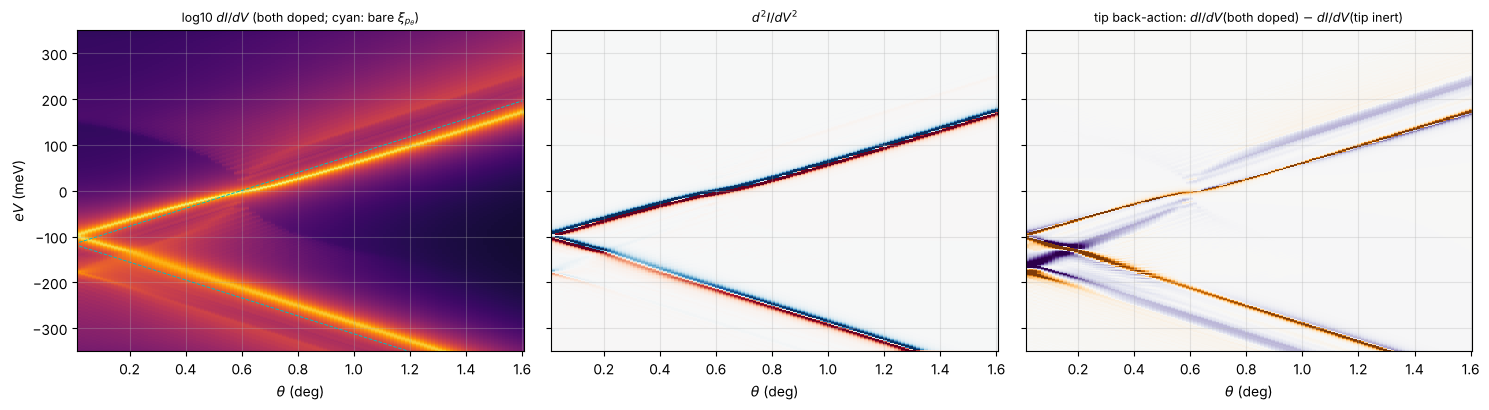

In [4]:
theta = np.linspace(0.02, 1.6, 120)
t0 = time.time()
for name, r in runs.items():
    A = np.zeros((2, theta.size, eps_v.size)); xi = np.zeros((2, theta.size))
    for ib, b in enumerate((+1, -1)):
        for it, t in enumerate(theta):
            pv = qtm.slg_probe_momentum(t)
            Sg = se.sigma_full_frequency_kernel(r["cfg"], pv, eps_v, r["q"], r["kernel"], r["qw"], band_ext=b)
            A[ib, it] = se.spectral_function_sample(r["cfg"], pv, eps_v, Sg, band_ext=b, eta_qp=2e-3)
            xi[ib, it] = se.quasiparticle_energy(r["cfg"], pv, b)
    r["smap"] = dict(theta_deg=theta, A=A, xi=xi, bands=np.array([+1, -1]), eps_values=eps_v)
    r["didv"] = qtm.slg_didv(r["smap"], tunneling_model="chiral")
    r["d2"] = qtm.bias_derivative(qtm.smooth_bias(r["didv"], eps_v, 1.5e-3), eps_v)
print(f"{2*theta.size} self-energies per configuration: {time.time()-t0:.1f} s")
const = qtm.slg_didv(runs["both doped"]["smap"], tunneling_model="constant")
print("chiral vs constant tunneling weight: max relative difference",
      np.max(np.abs(runs["both doped"]["didv"] - const)) / np.max(const))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
r = runs["both doped"]
axs[0].pcolormesh(theta, eps_v * 1e3, np.log10(r["didv"].T + 1e-2), shading="auto", cmap="inferno", vmin=-2, vmax=2.3)
for ib in range(2): axs[0].plot(theta, r["smap"]["xi"][ib] * 1e3, "c--", lw=0.7)
axs[0].set_title(r"log10 $dI/dV$ (both doped; cyan: bare $\xi_{p_\theta}$)", fontsize=9)
lim = np.percentile(np.abs(r["d2"]), 98)
axs[1].pcolormesh(theta, eps_v * 1e3, r["d2"].T, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axs[1].set_title(r"$d^2I/dV^2$", fontsize=9)
rel = r["didv"] - runs["tip inert"]["didv"]
lim = np.percentile(np.abs(rel), 99)
axs[2].pcolormesh(theta, eps_v * 1e3, rel.T, shading="auto", cmap="PuOr_r", vmin=-lim, vmax=lim)
axs[2].set_title(r"tip back-action: $dI/dV$(both doped) $-$ $dI/dV$(tip inert)", fontsize=9)
for a in axs: a.set_xlabel(r"$\theta$ (deg)")
axs[0].set_ylabel(r"$eV$ (meV)"); axs[0].set_ylim(-350, 350); plt.tight_layout(); plt.show()

## 4. Line cuts and satellites

Above $\theta(k_F)=0.6^\circ$ the conduction-band quasiparticle peak is above $E_F$ and the plasmon satellite
appears on the side away from $E_F$, displaced by roughly the plasmon energy at the dominant momentum
transfer. The offset is measured here from the **quasiparticle peak** (not from the bare $\xi$).

both doped: mean satellite offset from the QP peak for theta > 1 deg: 80.0 meV
tip inert: mean satellite offset from the QP peak for theta > 1 deg: 63.4 meV


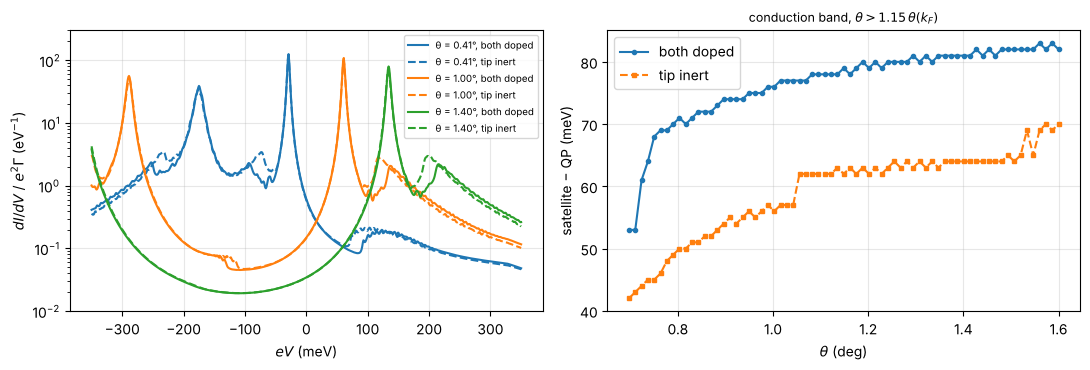

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for t_cut, c in ((0.4, "C0"), (1.0, "C1"), (1.4, "C2")):
    it = int(np.argmin(np.abs(theta - t_cut)))
    for name, ls in (("both doped", "-"), ("tip inert", "--")):
        ax[0].semilogy(eps_v * 1e3, runs[name]["didv"][it], ls, color=c, label=f"θ = {theta[it]:.2f}°, {name}")
ax[0].set_xlabel(r"$eV$ (meV)"); ax[0].set_ylabel(r"$dI/dV$ / $e^2\Gamma$ (eV$^{-1}$)"); ax[0].legend(fontsize=7)
ax[0].set_ylim(1e-2, 300)

def satellite_offset(didv_row, eps, xi):
    """QP peak near xi; satellite = largest local maximum on the far side of E_F (|eps| > |E_qp| + 15 meV)."""
    i_qp = np.argmax(np.where(np.abs(eps - xi) < 0.05, didv_row, 0)); e_qp = eps[i_qp]
    side = np.sign(e_qp) if abs(e_qp) > 0.01 else 1.0
    mask = (side * eps > side * e_qp + 0.015)
    loc = np.r_[False, (didv_row[1:-1] > didv_row[:-2]) & (didv_row[1:-1] > didv_row[2:]), False] & mask
    if not np.any(loc): return e_qp, np.nan
    i_sat = np.flatnonzero(loc)[np.argmax(didv_row[loc])]
    return e_qp, eps[i_sat] - e_qp

# only above theta(k_F): there the conduction-band QP peak is above E_F and well separated from the valence band
th_kF = qtm.momentum_to_twist(cfg.k_F)
plot_sel = theta > 1.15 * th_kF
for name, ls in (("both doped", "o-"), ("tip inert", "s--")):
    r = runs[name]; off = []
    for it in range(theta.size):
        off.append(satellite_offset(r["didv"][it], eps_v, r["smap"]["xi"][0, it])[1])
    ax[1].plot(theta[plot_sel], np.array(off)[plot_sel] * 1e3, ls, ms=3, label=name)
    sel = theta > 1.0
    print(f"{name}: mean satellite offset from the QP peak for theta > 1 deg: {np.nanmean(np.array(off)[sel])*1e3:.1f} meV")
ax[1].set_xlabel(r"$\theta$ (deg)"); ax[1].set_ylabel("satellite − QP (meV)"); ax[1].legend()
ax[1].set_title(r"conduction band, $\theta > 1.15\,\theta(k_F)$", fontsize=9)
plt.tight_layout(); plt.show()

* The quasiparticle branch is the QTM band-structure measurement $eV\simeq\xi_{\mathbf{p}_\theta}+\mathrm{Re}\,\Sigma$.
* The satellite tracks it at a nearly constant offset; the tip, when doped, adds its Drude weight to the
  in-phase plasmon and raises the satellite offset (back-action: about +17 meV here).
* $d^2I/dV^2$ sharpens the satellite edges (plasmon-emission thresholds).